# 01 – Data extraction and cleaning: 3rd deadlift attempt

**Project:** KETE – AI/ML project *Risk of failing the 3rd deadlift attempt* (Patrick Morgenegg, Niklas Grün)
**Data source:** [OpenPowerlifting](https://www.openpowerlifting.org) bulk CSV (Public Domain) [2]

This notebook turns the raw OpenPowerlifting bulk export into one clean, leakage-free, pseudonymised
table that a downstream (vibe-coded) application can load directly. It implements the specs in
[`docs/specs/`](../docs/specs/):

| Step | What happens | Spec |
|---|---|---|
| 1 | Download (or reuse) the bulk CSV and record its provenance | `02-data-source.md` |
| 2 | Load only the columns we need | `02-data-source.md` |
| 3 | Athlete history features from *earlier* meets | `05-features-and-leakage.md` |
| 4 | Filter funnel (rules C01–C13) | `03-data-preparation.md` |
| 5 | Decode attempts, label and features | `03-data-preparation.md`, `05-features-and-leakage.md` |
| 6 | Pseudonymise athletes, drop names | `03-data-preparation.md` |
| 7 | Athlete-level train / validation / test split (70/15/15) | `06-validation-split.md` |
| 8 | Exploration and numbers for the report | – |
| 9 | Export (Parquet, CSV, sample, metadata) and contract validation | `04-dataset-contract.md` |

**Decision point:** after the 2nd deadlift attempt. Everything used as a feature must be known at that
moment; the result of the 3rd attempt, best deadlift, total, place and points are never used.

> Run top to bottom (*Kernel → Restart & Run All*). The first run downloads ~170 MB; later runs reuse
> `data/raw/openpowerlifting-latest.zip`. Needs ~5 GB free RAM and 2–3 minutes after the download.

## 0. Setup

In [1]:
import hashlib
import json
import os
import re
import subprocess
import sys
import time
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| numpy", np.__version__, "| python", sys.version.split()[0])


def find_project_root(start: Path) -> Path:
    """Walk up from the working directory until the repository root (holds the dataset schema)."""
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "specs" / "dataset_schema.json").exists():
            return candidate
    raise FileNotFoundError("Start Jupyter from inside the repository (docs/specs/dataset_schema.json not found).")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
print("Project root:", PROJECT_ROOT)

pandas 3.0.5 | numpy 2.5.3 | python 3.13.16
Project root: /home/user/aiml


### Parameters

All tunable choices live in this one cell (tagged `parameters`, so it also works with
[papermill](https://papermill.readthedocs.io)). Changing a value changes the dataset – record any change in
`docs/decisions.md`.

| Environment variable | Purpose |
|---|---|
| `OPL_SOURCE_PATH` | Use a local `.zip` or `.csv` instead of downloading (offline use, restricted networks). Absolute, or relative to the repository root. |
| `OPL_ID_SALT` | Secret salt for the pseudonymous athlete id. Keep it constant – it also fixes the split. |

In [2]:
OPL_URL = "https://openpowerlifting.gitlab.io/opl-csv/files/openpowerlifting-latest.zip"
SOURCE_PATH = os.environ.get("OPL_SOURCE_PATH", "")  # optional local .zip/.csv – skips the download
FORCE_DOWNLOAD = False                                 # True = fetch a fresh snapshot even if one is cached

# Scope (report section 3.1)
DATE_MIN = os.environ.get("OPL_DATE_MIN", "2015-01-01")
DATE_MAX = os.environ.get("OPL_DATE_MAX", "2025-12-31")
# Separate exports (e.g. the 2026 time hold-out, decision D-19) use their own name and never touch the main dataset
EXPORT_NAME = os.environ.get("OPL_EXPORT_NAME", "deadlift3_attempts")
EVENTS = ["SBD"]                  # full power: squat and bench are finished before the deadlift
EXCLUDED_PLACES = ["NS", "DD"]    # no-show, doping disqualification
EXCLUDED_EQUIPMENT = ["Straps"]   # deadlift-with-straps exhibitions, not real meets
SANCTIONED_ONLY = True

# Plausibility bounds (kg) and jump cap (%)
WEIGHT_RANGE_KG = (20.0, 500.0)      # deadlift attempts
SQUAT_RANGE_KG = (10.0, 600.0)       # best squat of the meet (20–25 kg "bar squats" by injured lifters are real)
BENCH_RANGE_KG = (5.0, 400.0)        # best bench of the meet
BODYWEIGHT_RANGE_KG = (20.0, 300.0)
AGE_RANGE_YEARS = (5.0, 100.0)       # ages outside are treated as unknown, rows are kept
MAX_JUMP_PCT = 25.0                  # jumps above this are treated as data errors (~0.15 % of rows)

# Split (report section 4)
SPLIT_RATIOS = {"train": 0.70, "validation": 0.15, "test": 0.15}
ID_SALT = os.environ.get("OPL_ID_SALT", "kete-aiml-deadlift3-v1")

SAMPLE_SIZE = 5000
RANDOM_SEED = 42

In [3]:
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SAMPLE_DIR = PROJECT_ROOT / "data" / "sample"
for directory in (RAW_DIR, PROCESSED_DIR, SAMPLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SCHEMA_PATH = PROJECT_ROOT / "docs" / "specs" / "dataset_schema.json"
VALIDATOR = PROJECT_ROOT / "scripts" / "validate_dataset.py"
RAW_ZIP = RAW_DIR / "openpowerlifting-latest.zip"
MAIN_EXPORT = EXPORT_NAME == "deadlift3_attempts"
OUT_PARQUET = PROCESSED_DIR / f"{EXPORT_NAME}.parquet"
OUT_CSV = PROCESSED_DIR / f"{EXPORT_NAME}.csv"
OUT_META = PROCESSED_DIR / ("metadata.json" if MAIN_EXPORT else f"{EXPORT_NAME}.metadata.json")
OUT_SAMPLE = SAMPLE_DIR / "deadlift3_attempts_sample.csv" if MAIN_EXPORT else PROCESSED_DIR / f"{EXPORT_NAME}_sample.csv"

SCHEMA = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
assert abs(sum(SPLIT_RATIOS.values()) - 1) < 1e-9, "split ratios must sum to 1"
if "OPL_ID_SALT" not in os.environ:
    print("Note: OPL_ID_SALT not set – using the project default salt (fine for public data, see docs/specs/03).")

Note: OPL_ID_SALT not set – using the project default salt (fine for public data, see docs/specs/03).


## 1. Extract: download the bulk CSV

OpenPowerlifting publishes a nightly zip with one CSV (`openpowerlifting-YYYY-MM-DD-<commit>.csv`) plus
`LICENSE.txt` and `README.txt`. The zip is cached in `data/raw/` (git-ignored). Snapshot date and source
commit are parsed from the file name and stored in `metadata.json`, so every export can be traced back.

If `openpowerlifting.gitlab.io` is not reachable (some corporate or sandboxed networks), see
*Option B* in `docs/specs/02-data-source.md` and point `OPL_SOURCE_PATH` to the result.

In [4]:
def sha256_of(path: Path, chunk: int = 1 << 20) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()


def download(url: str, dest: Path) -> None:
    """Stream a file to disk; write to *.part first so an aborted download never looks complete."""
    tmp = dest.with_name(dest.name + ".part")
    request = urllib.request.Request(url, headers={"User-Agent": "kete-aiml-data-notebook"})
    with urllib.request.urlopen(request, timeout=120) as response, open(tmp, "wb") as out:
        total = int(response.headers.get("Content-Length") or 0)
        done, last_report = 0, 0.0
        while chunk := response.read(1 << 20):
            out.write(chunk)
            done += len(chunk)
            if time.time() - last_report > 5:
                print(f"  {done / 1e6:,.0f} MB" + (f" of {total / 1e6:,.0f} MB" if total else ""))
                last_report = time.time()
    tmp.replace(dest)


if SOURCE_PATH:
    source_file = Path(SOURCE_PATH).expanduser()
    if not source_file.is_absolute() and not source_file.exists():
        source_file = PROJECT_ROOT / source_file  # relative paths are relative to the repository root
    source_file, source_kind = source_file.resolve(), "local file (OPL_SOURCE_PATH)"
elif RAW_ZIP.exists() and not FORCE_DOWNLOAD:
    source_file, source_kind = RAW_ZIP, "cached download"
else:
    print(f"Downloading {OPL_URL} …")
    download(OPL_URL, RAW_ZIP)
    source_file, source_kind = RAW_ZIP, "fresh download"

if not source_file.exists():
    raise FileNotFoundError(source_file)
shown = source_file.relative_to(PROJECT_ROOT) if source_file.is_relative_to(PROJECT_ROOT) else source_file
print(f"Source: {shown} ({source_kind}, {source_file.stat().st_size / 1e6:,.1f} MB)")

Source: data/raw/openpowerlifting-latest.zip (local file (OPL_SOURCE_PATH), 170.3 MB)


In [5]:
def open_source_csv(path: Path):
    """Return (binary file handle, csv name) for the bulk CSV inside the zip, or for a plain .csv."""
    if path.suffix.lower() == ".zip":
        archive = zipfile.ZipFile(path)
        members = [m for m in archive.namelist() if m.lower().endswith(".csv")]
        if len(members) != 1:
            raise ValueError(f"expected exactly one CSV in {path.name}, found {members}")
        return archive.open(members[0]), Path(members[0]).name
    return open(path, "rb"), path.name


_, csv_member = open_source_csv(source_file)
match = re.search(r"openpowerlifting-(\d{4}-\d{2}-\d{2})-([0-9a-f]+)\.csv$", csv_member)
provenance = {
    "url": OPL_URL,
    "kind": source_kind,
    "file": source_file.name,
    "csv_member": csv_member,
    "snapshot_date": match.group(1) if match else None,
    "opl_commit": match.group(2) if match else None,
    "file_sha256": sha256_of(source_file),
    "file_modified_utc": datetime.fromtimestamp(source_file.stat().st_mtime, timezone.utc).isoformat(timespec="seconds"),
    "license": "Public Domain (OpenPowerlifting data license, LICENSE.txt in the zip)",
    "attribution": "This project uses data from the OpenPowerlifting project, https://www.openpowerlifting.org.",
}
provenance

{'url': 'https://openpowerlifting.gitlab.io/opl-csv/files/openpowerlifting-latest.zip',
 'kind': 'local file (OPL_SOURCE_PATH)',
 'file': 'openpowerlifting-latest.zip',
 'csv_member': 'openpowerlifting-2026-10-10-b55424f4.csv',
 'snapshot_date': '2026-10-10',
 'opl_commit': 'b55424f4',
 'file_sha256': 'c5d56bb325fe053cfd7fe38627c05b6289b36cdcfba736f601c66fcf80db7866',
 'file_modified_utc': '2026-10-10T09:46:36+00:00',
 'license': 'Public Domain (OpenPowerlifting data license, LICENSE.txt in the zip)',
 'attribution': 'This project uses data from the OpenPowerlifting project, https://www.openpowerlifting.org.'}

## 2. Load the relevant columns

The bulk CSV has 42 columns and >4 million rows. We load only what the pipeline needs. `MeetName` and
`Name` are needed temporarily (deduplication, pseudonymisation) and dropped in step 6.
`Best3DeadliftKg` is used **only** for the history of *earlier* meets – never for the current row.

In [6]:
RAW_COLUMNS = {
    "Name": "str", "Sex": "category", "Event": "category", "Equipment": "category",
    "Age": "float64", "AgeClass": "category", "BirthYearClass": "category",
    "BodyweightKg": "float64", "Best3SquatKg": "float64", "Best3BenchKg": "float64",
    "Best3DeadliftKg": "float64", "Deadlift1Kg": "float64", "Deadlift2Kg": "float64", "Deadlift3Kg": "float64",
    "Place": "str", "Tested": "str", "Federation": "category", "Date": "str",
    "MeetCountry": "category", "MeetName": "str", "Sanctioned": "str",
}

t0 = time.time()
handle, _ = open_source_csv(source_file)
with handle:
    raw = pd.read_csv(handle, usecols=list(RAW_COLUMNS), dtype=RAW_COLUMNS, low_memory=False)
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns in {time.time() - t0:.0f} s "
      f"({raw.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory)")
raw.head(3).drop(columns=["Name"])

Loaded 4,046,411 rows x 21 columns in 25 s (0.72 GB in memory)


,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,BodyweightKg,Best3SquatKg,Best3BenchKg,Deadlift1Kg,Deadlift2Kg,Deadlift3Kg,Best3DeadliftKg,Place,Tested,Federation,Date,MeetCountry,MeetName,Sanctioned
0,F,SBD,Raw,NaN,NaN,NaN,47.2,45.0,25.0,NaN,NaN,NaN,80.0,1,Yes,WP-India,2022-07-16,India,All Bengal Championships,Yes
1,F,SBD,Raw,NaN,NaN,NaN,48.0,40.0,27.5,NaN,NaN,NaN,70.0,2,Yes,WP-India,2022-07-16,India,All Bengal Championships,Yes
2,F,SBD,Raw,NaN,NaN,NaN,47.4,32.5,25.0,NaN,NaN,NaN,77.5,3,Yes,WP-India,2022-07-16,India,All Bengal Championships,Yes


In [7]:
# Quick profile of the raw data: share of missing values in the columns that matter most
profile = pd.DataFrame({
    "missing_share": raw.isna().mean().round(4),
    "example": raw.drop(columns=["Name"]).iloc[0].reindex(raw.columns),
}).drop(index="Name")
print("Date range:", raw["Date"].min(), "→", raw["Date"].max())
print("Events:", raw["Event"].value_counts().to_dict())
profile.sort_values("missing_share", ascending=False)

Date range: 1964-09-05 → 2026-10-04
Events: {'SBD': 2922266, 'B': 801988, 'D': 219583, 'BD': 75941, 'S': 19960, 'SB': 4185, 'SD': 2488}


,missing_share,example
Deadlift3Kg,0.6521,NaN
Deadlift2Kg,0.6393,NaN
Deadlift1Kg,0.6331,NaN
Age,0.3617,NaN
BirthYearClass,0.3408,NaN
Best3SquatKg,0.3033,45.0
AgeClass,0.2696,NaN
Best3DeadliftKg,0.2517,80.0
Tested,0.2375,Yes
Best3BenchKg,0.1126,25.0


## 3. Athlete history from earlier meets (candidate features)

For every athlete and meet date we compute, from **all** OpenPowerlifting entries (any event, any year):

* `prev_best_deadlift_kg` – best successful deadlift (within the plausible weight range) in any meet *strictly before* this date,
* `prev_meets_count` – number of distinct earlier meet dates.

Both are known before the meet starts, so they are leakage-free (report section 7.3, *next steps*).
Same-day entries are excluded on purpose: a second division entry on the same day must not leak the
current result.

In [8]:
history = (
    raw[["Name", "Date"]]
    .assign(best_dl=raw["Best3DeadliftKg"].where(raw["Best3DeadliftKg"].between(*WEIGHT_RANGE_KG)))
    .groupby(["Name", "Date"], sort=True)["best_dl"].max()
    .reset_index()
)
# ISO dates sort chronologically, so within each name the rows are in time order.
running_best = history.groupby("Name", sort=False)["best_dl"].cummax()
running_best = running_best.groupby(history["Name"], sort=False).ffill()  # carry the best over meets without a deadlift
history["prev_best_deadlift_kg"] = running_best.groupby(history["Name"], sort=False).shift(1)
history["prev_meets_count"] = history.groupby("Name", sort=False).cumcount()
history = history.drop(columns="best_dl")
print(f"History table: {len(history):,} athlete-days")

History table: 3,649,190 athlete-days


## 4. Filter funnel (rules C01–C13)

Each rule is applied in order; the funnel table records how many rows every rule removes. The rules and
their rationale are specified in `docs/specs/03-data-preparation.md`.

In [9]:
funnel = [{"rule": "C00", "description": "raw OpenPowerlifting rows", "removed": 0, "remaining": len(raw)}]


def apply_rule(frame: pd.DataFrame, rule: str, description: str, keep: pd.Series) -> pd.DataFrame:
    kept = frame.loc[keep.fillna(False).astype(bool)]
    funnel.append({"rule": rule, "description": description,
                   "removed": len(frame) - len(kept), "remaining": len(kept)})
    return kept


df = raw
df = apply_rule(df, "C01", f"meet date within {DATE_MIN} … {DATE_MAX}",
                (df["Date"] >= DATE_MIN) & (df["Date"] <= DATE_MAX))
df = apply_rule(df, "C02", f"event in {EVENTS} (squat and bench done before the deadlift)",
                df["Event"].isin(EVENTS))
if SANCTIONED_ONLY:
    df = apply_rule(df, "C03", "sanctioned meets only", df["Sanctioned"].fillna("Yes") != "No")
df = apply_rule(df, "C04", f"place not in {EXCLUDED_PLACES} (no-show, doping DQ)",
                ~df["Place"].isin(EXCLUDED_PLACES))
df = apply_rule(df, "C05", f"equipment not in {EXCLUDED_EQUIPMENT}",
                ~df["Equipment"].isin(EXCLUDED_EQUIPMENT))
df = apply_rule(df, "C06", "2nd and 3rd deadlift attempt recorded (attempt-level data)",
                df["Deadlift2Kg"].notna() & df["Deadlift3Kg"].notna()
                & (df["Deadlift2Kg"] != 0) & (df["Deadlift3Kg"] != 0))
df = apply_rule(df, "C07", "valid best squat and bench (lifter still in the meet at decision time)",
                (df["Best3SquatKg"] > 0) & (df["Best3BenchKg"] > 0))
df = apply_rule(df, "C08", f"bodyweight recorded and within {BODYWEIGHT_RANGE_KG} kg",
                df["BodyweightKg"].between(*BODYWEIGHT_RANGE_KG))

dl1, dl2, dl3 = df["Deadlift1Kg"].abs(), df["Deadlift2Kg"].abs(), df["Deadlift3Kg"].abs()
df = apply_rule(df, "C09", "attempt, squat and bench weights within plausible ranges",
                dl2.between(*WEIGHT_RANGE_KG) & dl3.between(*WEIGHT_RANGE_KG)
                & (dl1.isna() | dl1.between(*WEIGHT_RANGE_KG))
                & df["Best3SquatKg"].between(*SQUAT_RANGE_KG) & df["Best3BenchKg"].between(*BENCH_RANGE_KG))

# Rules of the sport: the bar never gets lighter, and after a good lift the next attempt must be heavier.
dl1, dl2, dl3 = df["Deadlift1Kg"].abs(), df["Deadlift2Kg"].abs(), df["Deadlift3Kg"].abs()
dl1_good, dl2_good = df["Deadlift1Kg"] > 0, df["Deadlift2Kg"] > 0
progression_ok = (dl3 >= dl2) & ~(dl2_good & (dl3 == dl2))
progression_ok &= dl1.isna() | ((dl2 >= dl1) & ~(dl1_good & (dl2 == dl1)))
df = apply_rule(df, "C10", "attempt progression consistent (no decrease, increase after a good lift)", progression_ok)

jump_pct = (df["Deadlift3Kg"].abs() - df["Deadlift2Kg"].abs()) / df["Deadlift2Kg"].abs() * 100
df = apply_rule(df, "C11", f"jump to 3rd attempt ≤ {MAX_JUMP_PCT:g} %", jump_pct <= MAX_JUMP_PCT)

# The same lifter is often listed once per division (e.g. Open and Junior) with identical attempts.
dedup_key = ["Name", "Date", "Federation", "MeetName", "Deadlift1Kg", "Deadlift2Kg", "Deadlift3Kg"]
df = apply_rule(df, "C12", "one row per lifter and meet (drop duplicate division entries)",
                ~df.duplicated(dedup_key, keep="first"))
df = apply_rule(df, "C13", "label defined (3rd attempt good or failed)", df["Deadlift3Kg"].notna())

funnel_df = pd.DataFrame(funnel)
funnel_df["remaining_share"] = (funnel_df["remaining"] / funnel_df["remaining"].iloc[0]).round(4)
funnel_df

,rule,description,removed,remaining,remaining_share
0,C00,raw OpenPowerlifting rows,0,4046411,1.0000
1,C01,meet date within 2015-01-01 … 2025-12-31,1441862,2604549,0.6437
2,C02,event in ['SBD'] (squat and bench done before ...,665756,1938793,0.4791
3,C03,sanctioned meets only,5158,1933635,0.4779
4,C04,"place not in ['NS', 'DD'] (no-show, doping DQ)",16865,1916770,0.4737
5,C05,equipment not in ['Straps'],1,1916769,0.4737
6,C06,2nd and 3rd deadlift attempt recorded (attempt...,953557,963212,0.2380
7,C07,valid best squat and bench (lifter still in th...,20034,943178,0.2331
8,C08,"bodyweight recorded and within (20.0, 300.0) kg",196,942982,0.2330
9,C09,"attempt, squat and bench weights within plausi...",80,942902,0.2330


## 5. Decode attempts, label and features

OpenPowerlifting encodes a failed attempt as a **negative** weight (−230 = failed with 230 kg).
We split every attempt into its absolute weight and a success flag:

* label `dl3_failed` = 1 if `Deadlift3Kg < 0` (attempt fails), else 0
* `dl3_jump_pct` = (|DL3| − |DL2|) / |DL2| × 100 (report section 3.3)

All weights are in kg (OpenPowerlifting already converts lb meets with 1 lb = 0.45359237 kg).
Age is mapped to the IPF-style groups used in the report: Sub-Junior (≤18), Junior (19–23),
Open (24–39), Masters (40+), Unknown. Ages outside 5–100 years are treated as unknown (the row is kept).

In [10]:
AGE_GROUP_ORDER = ["Sub-Junior", "Junior", "Open", "Masters", "Unknown"]
SJ, JR, OP, MA = AGE_GROUP_ORDER[:4]
BIRTH_YEAR_CLASS_TO_GROUP = {"14-18": SJ, "19-23": JR, "24-39": OP,
                             "40-49": MA, "50-59": MA, "60-69": MA, "70-999": MA}
AGE_CLASS_TO_GROUP = {"5-12": SJ, "13-15": SJ, "16-17": SJ, "18-19": JR, "20-23": JR, "24-34": OP, "35-39": OP,
                      **{c: MA for c in ["40-44", "45-49", "50-54", "55-59", "60-64", "65-69",
                                         "70-74", "75-79", "80-84", "85-89", "90-999"]}}


def age_group(frame: pd.DataFrame) -> pd.Series:
    """IPF-style age group. Priority: BirthYearClass (IPF definition) → exact Age → AgeClass → Unknown."""
    from_byc = frame["BirthYearClass"].astype(object).map(BIRTH_YEAR_CLASS_TO_GROUP)
    age = frame["Age"].where(frame["Age"].between(*AGE_RANGE_YEARS))
    from_age = pd.cut(age, [-np.inf, 19, 24, 40, np.inf], right=False, labels=[SJ, JR, OP, MA]).astype(object)
    from_ac = frame["AgeClass"].astype(object).map(AGE_CLASS_TO_GROUP)
    return from_byc.fillna(from_age).fillna(from_ac).fillna("Unknown").astype(str)


out = pd.DataFrame(index=df.index)
out["meet_date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
out["meet_year"] = out["meet_date"].dt.year.astype("int16")
out["federation"] = df["Federation"].astype("str")
out["meet_country"] = df["MeetCountry"].astype(object)
out["tested"] = (df["Tested"] == "Yes").astype("int8")

out["dl3_weight_kg"] = df["Deadlift3Kg"].abs().round(2)
out["dl2_weight_kg"] = df["Deadlift2Kg"].abs().round(2)
out["dl2_success"] = (df["Deadlift2Kg"] > 0).astype("int8")
out["dl3_jump_pct"] = ((out["dl3_weight_kg"] - out["dl2_weight_kg"]) / out["dl2_weight_kg"] * 100).round(2)
out["bodyweight_kg"] = df["BodyweightKg"].round(2)
out["age_class_group"] = pd.Categorical(age_group(df), categories=AGE_GROUP_ORDER)
out["equipment"] = df["Equipment"].astype("str")
out["best_squat_kg"] = df["Best3SquatKg"].round(2)
out["best_bench_kg"] = df["Best3BenchKg"].round(2)

out["dl3_jump_kg"] = (out["dl3_weight_kg"] - out["dl2_weight_kg"]).round(2)
out["dl1_weight_kg"] = df["Deadlift1Kg"].abs().round(2)
out["dl1_success"] = (df["Deadlift1Kg"] > 0).astype("Int8").mask(df["Deadlift1Kg"].isna())
out["dl2_jump_pct"] = ((out["dl2_weight_kg"] - out["dl1_weight_kg"]) / out["dl1_weight_kg"] * 100).round(2)
out["dl3_to_bodyweight"] = (out["dl3_weight_kg"] / out["bodyweight_kg"]).round(4)
out["dl3_to_best_squat"] = (out["dl3_weight_kg"] / out["best_squat_kg"]).round(4)
out["age_years"] = df["Age"].where(df["Age"].between(*AGE_RANGE_YEARS))

hist = df[["Name", "Date"]].merge(history, on=["Name", "Date"], how="left", validate="many_to_one")
out["prev_best_deadlift_kg"] = hist["prev_best_deadlift_kg"].to_numpy()
out["prev_meets_count"] = hist["prev_meets_count"].to_numpy().astype("int32")

out["sex"] = df["Sex"].astype("str")
out["dl3_failed"] = (df["Deadlift3Kg"] < 0).astype("int8")

print(f"{len(out):,} rows, {out.shape[1]} columns")
out.head()

879,465 rows, 25 columns


,meet_date,meet_year,federation,meet_country,tested,dl3_weight_kg,dl2_weight_kg,dl2_success,dl3_jump_pct,bodyweight_kg,age_class_group,equipment,best_squat_kg,best_bench_kg,dl3_jump_kg,dl1_weight_kg,dl1_success,dl2_jump_pct,dl3_to_bodyweight,dl3_to_best_squat,age_years,prev_best_deadlift_kg,prev_meets_count,sex,dl3_failed
432,2019-01-26,2019,USA-UA,USA,0,175.0,162.5,1,7.69,142.0,Junior,Raw,165.0,105.0,12.5,155.0,1,4.84,1.2324,1.0606,19.0,NaN,0,M,0
433,2019-01-26,2019,USA-UA,USA,0,207.5,182.5,1,13.70,137.5,Sub-Junior,Raw,200.0,142.5,25.0,167.5,1,8.96,1.5091,1.0375,17.0,210.0,2,M,0
434,2019-01-26,2019,USA-UA,USA,0,235.0,227.5,1,3.30,133.8,Junior,Raw,200.0,155.0,7.5,215.0,1,5.81,1.7564,1.1750,22.0,NaN,0,M,0
437,2019-01-26,2019,USA-UA,USA,0,300.0,295.0,1,1.69,147.8,Open,Raw,232.5,167.5,5.0,282.5,1,4.42,2.0298,1.2903,29.0,295.0,3,M,1
438,2019-01-26,2019,USA-UA,USA,0,320.0,300.0,1,6.67,133.8,Open,Raw,287.5,190.0,20.0,287.5,1,4.35,2.3916,1.1130,33.0,320.0,13,M,0


## 6. Pseudonymise

* `athlete_id` = first 16 hex characters of SHA-256(`OPL_ID_SALT` + OpenPowerlifting `Name`).
  OpenPowerlifting already disambiguates namesakes (`John Doe #1`, `John Doe #2`), so one name = one person.
* `record_id` = hash of athlete, date, federation, meet, equipment and attempts – stable across re-runs.
* `Name` and `MeetName` are **not** exported (report section 3.4 / 6.5). No output column allows a lookup of
  a person; the app must not display or search individual athletes.

In [11]:
def short_hash(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]


unique_names = pd.Series(df["Name"].unique())
name_to_id = dict(zip(unique_names, unique_names.map(lambda n: short_hash(ID_SALT + n))))
out.insert(0, "athlete_id", df["Name"].map(name_to_id))
assert out["athlete_id"].nunique() == len(unique_names), "hash collision between athletes"

def fmt_attempt(values: pd.Series) -> pd.Series:
    return values.map(lambda v: "" if pd.isna(v) else f"{v:g}")


record_key = (out["athlete_id"] + "|" + df["Date"] + "|" + df["Federation"].astype(str) + "|"
              + df["MeetName"].fillna("") + "|" + df["Equipment"].astype(str) + "|"
              + fmt_attempt(df["Deadlift1Kg"]) + "|" + fmt_attempt(df["Deadlift2Kg"]) + "|"
              + fmt_attempt(df["Deadlift3Kg"]))
out.insert(0, "record_id", record_key.map(short_hash))
assert out["record_id"].is_unique, "record_id must be unique"

del record_key, name_to_id, unique_names
print(f"{out['athlete_id'].nunique():,} athletes, {len(out):,} records")

343,047 athletes, 879,465 records


## 7. Athlete-level split: train / validation / test

All meets of an athlete land in exactly **one** subset, so the model is always evaluated on people it has
never seen (report section 4.1). The assignment is a deterministic function of `athlete_id`:
`u = int(athlete_id[:8], 16) / 16^8` → train if `u < 0.70`, validation if `u < 0.85`, else test.
Because `athlete_id` is a salted hash, `u` is uniformly distributed (a random draw), and the same athlete
keeps its subset when the data is refreshed with newer meets.

Terminology (fixed for the whole project): **validation** = model selection and threshold tuning;
**test** = touched exactly once for the final evaluation.

In [12]:
bounds = np.cumsum([SPLIT_RATIOS["train"], SPLIT_RATIOS["validation"]])
u = out["athlete_id"].str[:8].map(lambda h: int(h, 16)) / 16**8
out.insert(2, "split", pd.Categorical(
    np.select([u < bounds[0], u < bounds[1]], ["train", "validation"], default="test"),
    categories=list(SPLIT_RATIOS)))

assert out.groupby("athlete_id")["split"].nunique().max() == 1, "an athlete appears in more than one split"

split_summary = (out.groupby("split", observed=True)
                 .agg(athletes=("athlete_id", "nunique"), records=("record_id", "size"),
                      fail_rate=("dl3_failed", "mean")))
split_summary["athlete_share"] = (split_summary["athletes"] / split_summary["athletes"].sum()).round(4)
split_summary["record_share"] = (split_summary["records"] / split_summary["records"].sum()).round(4)
split_summary["fail_rate"] = split_summary["fail_rate"].round(4)
split_summary

,athletes,records,fail_rate,athlete_share,record_share
split,,,,,
train,240340,616069,0.3875,0.7006,0.7005
validation,51399,131443,0.3860,0.1498,0.1495
test,51308,131953,0.3872,0.1496,0.1500


## 8. Exploration

Descriptive checks only – no model is fitted here. All rates below are computed on the **train** split so
that nothing learned from validation/test leaks into later decisions (e.g. the rule-of-thumb threshold).

In [13]:
train = out[out["split"] == "train"]
print(f"Failure rate of 3rd attempts (train): {train['dl3_failed'].mean():.1%}")

JUMP_BINS = [-0.01, 0, 2.5, 5, 7.5, 10, 15, MAX_JUMP_PCT]
jump_bin = pd.cut(train["dl3_jump_pct"], JUMP_BINS)
by_jump = (train.assign(jump_bin=jump_bin, dl2=train["dl2_success"].map({1: "2nd good", 0: "2nd failed"}))
           .pivot_table(index="jump_bin", columns="dl2", values="dl3_failed", aggfunc=["mean", "size"], observed=True))
by_jump.round(3)

Failure rate of 3rd attempts (train): 38.7%


mean                size          
dl2          2nd failed 2nd good 2nd failed  2nd good
jump_bin                                             
(-0.01, 0.0]      0.647      NaN    52531.0       NaN
(0.0, 2.5]        0.523    0.462     6981.0   65632.0
(2.5, 5.0]        0.510    0.360     6266.0  234650.0
(5.0, 7.5]        0.541    0.328     2496.0  156689.0
(7.5, 10.0]       0.540    0.330      869.0   58991.0
(10.0, 15.0]      0.594    0.338      406.0   24726.0
(15.0, 25.0]      0.537    0.330      108.0    5724.0

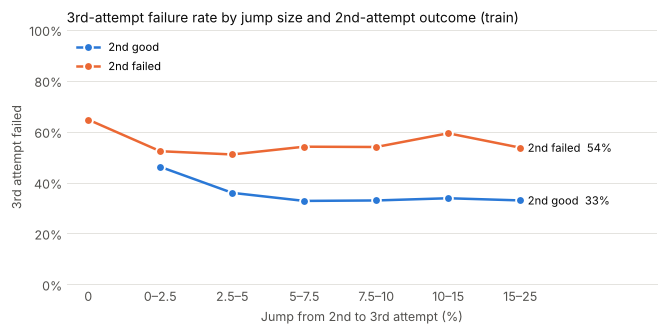

In [14]:
# Failure rate of the 3rd attempt by jump size, split by the outcome of the 2nd attempt
SERIES = {"2nd good": "#2a78d6", "2nd failed": "#eb6834"}   # categorical slots 1–2 (validated pair)
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

rates = by_jump["mean"]
labels = ["0", "0–2.5", "2.5–5", "5–7.5", "7.5–10", "10–15", f"15–{MAX_JUMP_PCT:g}"][: len(rates)]
x = np.arange(len(rates))

fig, ax = plt.subplots(figsize=(7.5, 3.8), dpi=90)
for name, color in SERIES.items():
    if name in rates:
        y = rates[name].to_numpy()
        ax.plot(x, y, color=color, linewidth=2, marker="o", markersize=7,
                markeredgecolor="white", markeredgewidth=1.5, label=name)
        last = np.flatnonzero(~np.isnan(y))[-1]
        ax.annotate(f"{name}  {y[last]:.0%}", (x[last], y[last]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK)
ax.set_xticks(x, labels)
ax.set_xlabel("Jump from 2nd to 3rd attempt (%)", color=INK_MUTED)
ax.set_ylabel("3rd attempt failed", color=INK_MUTED)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 1)
ax.set_title("3rd-attempt failure rate by jump size and 2nd-attempt outcome (train)", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK_MUTED, length=0)
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_xlim(-0.3, len(x) - 0.3 + 1.2)
plt.tight_layout()
plt.show()

**Reading the chart (snapshot 2026-10-10, train split).** The outcome of the 2nd attempt separates the
classes far more than the jump size: after a failed 2nd attempt about half or more of the 3rd attempts fail,
after a good one about a third. The relation to the jump is **not** monotonic – very small jumps after a
good 2nd attempt fail *more* often (≈46 %), presumably because coaches choose small jumps when the 2nd
attempt already looked heavy. Consequences for chapter 5: a pure "fails if jump > x %" rule of thumb will be
a weak baseline, and `dl2_success` is a key feature. Re-check these numbers after every data refresh.

In [15]:
# Segment overview (descriptive; the fairness evaluation itself happens on the model's predictions)
def segment_table(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    table = frame.groupby(column, observed=True).agg(records=("dl3_failed", "size"), fail_rate=("dl3_failed", "mean"))
    table["share"] = table["records"] / table["records"].sum()
    return table.round(4)


pd.concat({c: segment_table(train, c) for c in ["sex", "age_class_group", "equipment"]}, names=["segment", "value"])

records  fail_rate   share
segment         value                                 
sex             F            207049     0.3379  0.3361
                M            408959     0.4126  0.6638
                Mx               61     0.2459  0.0001
age_class_group Sub-Junior    77006     0.3505  0.1250
                Junior       154239     0.4034  0.2504
                Open         247566     0.4029  0.4018
                Masters       96440     0.3560  0.1565
                Unknown       40818     0.3780  0.0663
equipment       Multi-ply      4331     0.5038  0.0070
                Raw          491930     0.3748  0.7985
                Single-ply    41128     0.4652  0.0668
                Unlimited       541     0.4732  0.0009
                Wraps         78139     0.4195  0.1268

In [16]:
# Summary of numeric features and missingness of the candidate features (train split)
numeric_cols = [c["name"] for c in SCHEMA["columns"]
                if c["dtype"] in ("int", "float") and c["role"] in ("feature", "decision_input", "candidate_feature")]
summary = train[numeric_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
summary["missing_share"] = train[numeric_cols].isna().mean()
summary.round(3)

,count,mean,std,min,1%,50%,99%,max,missing_share
dl3_weight_kg,616069.0,201.077218,60.763402,25.0,82.5,202.5,336.2348,470.0,0.000
dl2_weight_kg,616069.0,192.413949,59.469736,20.4,75.0,192.5,325.0,460.0,0.000
dl2_success,616069.0,0.886933,0.316675,0.0,0.0,1.0,1.0,1.0,0.000
dl3_jump_pct,616069.0,4.811855,3.072353,0.0,0.0,4.48,15.0,25.0,0.000
bodyweight_kg,616069.0,83.555581,21.151761,20.0,46.6268,81.43,146.55,285.0,0.000
best_squat_kg,616069.0,173.632138,62.385648,10.0,57.5,170.0,335.0,552.5,0.000
best_bench_kg,616069.0,109.625534,44.764891,6.8,35.0,110.0,225.0,396.89,0.000
dl3_jump_kg,616069.0,8.663269,5.347597,0.0,0.0,7.5,25.0,90.0,0.000
dl1_weight_kg,616008.0,180.313809,57.104494,20.0,67.5,180.0,307.5,449.06,0.000
dl1_success,616008.0,0.953241,0.211123,0.0,0.0,1.0,1.0,1.0,0.000


### Numbers for the report

Copy these into the placeholders of the project report (sections 3.1 and 4.2).

In [17]:
n_records, n_athletes = len(out), out["athlete_id"].nunique()
report_numbers = {
    "period": f"{out['meet_date'].min():%Y-%m-%d} – {out['meet_date'].max():%Y-%m-%d}",
    "records_after_cleaning": n_records,
    "athletes_after_cleaning": n_athletes,
    "failed_third_attempt_share": round(float(out["dl3_failed"].mean()), 4),
    "snapshot": f"{provenance['snapshot_date']} (commit {provenance['opl_commit']})",
}
lines = [
    "| Kennzahl | Wert |", "|---|---|",
    f"| Betrachtungszeitraum | {report_numbers['period']} |",
    f"| Datensätze nach Bereinigung | {n_records:,} |".replace(",", "'"),
    f"| Athletinnen und Athleten | {n_athletes:,} |".replace(",", "'"),
    f"| Anteil gescheiterter 3. Versuche | {report_numbers['failed_third_attempt_share']:.1%} |",
    f"| OpenPowerlifting-Snapshot | {report_numbers['snapshot']} |",
    "", "| Teilmenge | Athleten | Versuche | Anteil «scheitert» |", "|---|---|---|---|",
]
for name, row in split_summary.iterrows():
    lines.append(f"| {name} | {int(row.athletes):,} | {int(row.records):,} | {row.fail_rate:.1%} |".replace(",", "'"))
print("\n".join(lines))

| Kennzahl | Wert |
|---|---|
| Betrachtungszeitraum | 2015-01-01 – 2025-12-30 |
| Datensätze nach Bereinigung | 879'465 |
| Athletinnen und Athleten | 343'047 |
| Anteil gescheiterter 3. Versuche | 38.7% |
| OpenPowerlifting-Snapshot | 2026-10-10 (commit b55424f4) |

| Teilmenge | Athleten | Versuche | Anteil «scheitert» |
|---|---|---|---|
| train | 240'340 | 616'069 | 38.8% |
| validation | 51'399 | 131'443 | 38.6% |
| test | 51'308 | 131'953 | 38.7% |


## 9. Export and validate

Outputs (see `docs/specs/04-dataset-contract.md`):

| File | Content | In git? |
|---|---|---|
| `data/processed/deadlift3_attempts.parquet` | full dataset, typed (preferred for Python) | no |
| `data/processed/deadlift3_attempts.csv` | full dataset, UTF-8, `,`-separated, ISO dates (for any tool / JS) | no |
| `data/processed/metadata.json` | provenance, parameters, funnel, split counts, category levels, input ranges | yes |
| `data/sample/deadlift3_attempts_sample.csv` | 5,000 random rows for app development and tests | yes |

In [18]:
column_order = [c["name"] for c in SCHEMA["columns"]]
assert set(column_order) == set(out.columns), set(column_order) ^ set(out.columns)
final = out[column_order].sort_values(["meet_date", "record_id"]).reset_index(drop=True)
for column in ("equipment", "sex"):
    allowed = next(c["allowed"] for c in SCHEMA["columns"] if c["name"] == column)
    assert final[column].isin(allowed).all(), f"unexpected {column} values: {set(final[column]) - set(allowed)}"
    final[column] = pd.Categorical(final[column], categories=allowed)

final.to_parquet(OUT_PARQUET, index=False)
final.to_csv(OUT_CSV, index=False, date_format="%Y-%m-%d")
sample = final.sample(n=min(SAMPLE_SIZE, len(final)), random_state=RANDOM_SEED).sort_values(["meet_date", "record_id"])
sample.to_csv(OUT_SAMPLE, index=False, date_format="%Y-%m-%d")

for path in (OUT_PARQUET, OUT_CSV, OUT_SAMPLE):
    print(f"{path.relative_to(PROJECT_ROOT)}: {path.stat().st_size / 1e6:,.1f} MB")

data/processed/deadlift3_attempts.parquet: 48.4 MB
data/processed/deadlift3_attempts.csv: 144.3 MB
data/sample/deadlift3_attempts_sample.csv: 0.8 MB


In [19]:
def numeric_ranges(frame: pd.DataFrame) -> dict:
    """Train-split ranges for app input validation and defaults (never computed on validation/test)."""
    ranges = {}
    for column in numeric_cols:
        values = frame[column].dropna().astype("float64")
        ranges[column] = {"min": float(values.min()), "p01": float(values.quantile(0.01)),
                          "median": float(values.median()), "p99": float(values.quantile(0.99)),
                          "max": float(values.max())}
    return ranges


metadata = {
    "dataset": SCHEMA["dataset"],
    "schema_version": SCHEMA["schema_version"],
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "notebook": "notebooks/01_data_extraction_and_cleaning.ipynb",
    "source": provenance,
    "parameters": {
        "date_min": DATE_MIN, "date_max": DATE_MAX, "events": EVENTS, "excluded_places": EXCLUDED_PLACES,
        "excluded_equipment": EXCLUDED_EQUIPMENT, "sanctioned_only": SANCTIONED_ONLY,
        "weight_range_kg": WEIGHT_RANGE_KG, "squat_range_kg": SQUAT_RANGE_KG, "bench_range_kg": BENCH_RANGE_KG,
        "bodyweight_range_kg": BODYWEIGHT_RANGE_KG, "age_range_years": AGE_RANGE_YEARS, "max_jump_pct": MAX_JUMP_PCT, "split_ratios": SPLIT_RATIOS,
        "id_salt_source": "env OPL_ID_SALT" if "OPL_ID_SALT" in os.environ else "project default",
        "id_salt_fingerprint": hashlib.sha256(ID_SALT.encode()).hexdigest()[:8],
        "sample_size": len(sample), "random_seed": RANDOM_SEED,
    },
    "funnel": funnel,
    "summary": {**report_numbers, "label_positive_class": "dl3_failed = 1 (3rd attempt fails)"},
    "splits": {name: {"athletes": int(r.athletes), "records": int(r.records), "fail_rate": float(r.fail_rate)}
               for name, r in split_summary.iterrows()},
    "category_levels": {
        "equipment": [e for e in final["equipment"].cat.categories if (final["equipment"] == e).any()],
        "age_class_group": AGE_GROUP_ORDER,
        "sex": [s for s in final["sex"].cat.categories if (final["sex"] == s).any()],
    },
    "feature_ranges_train": numeric_ranges(final[final["split"] == "train"]),
    "files": {"parquet": str(OUT_PARQUET.relative_to(PROJECT_ROOT)), "csv": str(OUT_CSV.relative_to(PROJECT_ROOT)),
              "sample_csv": str(OUT_SAMPLE.relative_to(PROJECT_ROOT)), "schema": "docs/specs/dataset_schema.json"},
}
OUT_META.write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str) + "\n", encoding="utf-8")
print("wrote", OUT_META.relative_to(PROJECT_ROOT))

wrote data/processed/metadata.json


In [20]:
# Contract check: the same validator the app's CI and the skills use
for target in (OUT_PARQUET, OUT_SAMPLE):
    result = subprocess.run([sys.executable, str(VALIDATOR), str(target), "--metadata", str(OUT_META)],
                            capture_output=True, text=True)
    print(result.stdout.strip() or result.stderr.strip())
    if result.returncode != 0:
        raise RuntimeError(f"{target.name} violates the dataset contract (see output above)")

deadlift3_attempts.parquet: 879,465 rows, 28 columns, schema 1.0.0
  OK – contract satisfied


deadlift3_attempts_sample.csv: 5,000 rows, 28 columns, schema 1.0.0
  OK – contract satisfied


## Next steps

* Fill the report placeholders with the numbers printed above (sections 3.1, 4.2).
* Model training, threshold selection and fairness checks consume `deadlift3_attempts.parquet`
  as described in `docs/specs/07-evaluation-and-fairness.md`.
* The coach-facing app follows `docs/specs/08-app-integration.md`.

**References**
[1] Michelucci, U. KETE Course Lecture Notes (DE), Version 6.0.
[2] OpenPowerlifting Project. OpenPowerlifting database (Public Domain). https://www.openpowerlifting.org